# Regularized constitutive laws and where the plug is

Almost every computation of a Herschel–Bulkley (HB) flow in two or three dimensions, and many data fits, replace the two-branch law (rigid below the yield stress, flowing above it) by a smooth single-branch approximation. The most common are the **Papanastasiou** exponential form and the **bi-viscosity** model. They make the problem easy for standard solvers, but they change the material: the "rigid" region now creeps slowly, and the plug that appears in a plot of a regularized solution is not a rigid region but the output of a *classification rule*. This notebook shows how the regularizations behave, why their parameter must be judged in dimensionless form, how a regularized pipe flow converges to the exact solution, and why the two limits $\varepsilon\to 0$ (plug threshold) and $M\to\infty$ (regularization) cannot be taken in either order.

### Where this is in the review
* **Sec. VII F, "Regularized constitutive laws"**: the Papanastasiou form, **Eq. (29)**, the bi-viscosity model, the Bercovier–Engelman and Souza Mendes–Dutra forms, the residual divergence for $n<1$, and the dimensionless parameter $M = m\dot\gamma_y$; **Fig. 11** (script `scripts/fig11_regularization.py`).
* **Sec. VII G, "Locating the plug: diagnostics and noncommuting limits"**: the rate-defined plug radius, **Eq. (30)**, its two limits and the stress criterion; **Fig. 12** (script `scripts/fig12_hbp_pipe.py`).
* Background: the exact pipe solution, **Sec. VII A, Eqs. (18)–(19)** and Fig. 8; the rate scale $\dot\gamma_y=(\sigma_y/K)^{1/n}$, **Sec. IV C**; the HB–Papanastasiou row of **Table X**; the regularization row of the error budget, **Table IX**; unregularized methods, **Sec. VII H** and **Supplementary Note S10**.
* Figure data used for the checks: `data/figure_data/fig11_regularization.csv`, `data/figure_data/fig12_hbp_pipe.csv`.

### Learning objectives
After working through this notebook you should be able to
1. write down the Papanastasiou and bi-viscosity laws and explain which part of the HB viscosity each one regularizes;
2. explain why a bare value of $m$ (units of time) means nothing and why $M=m\dot\gamma_y$ does;
3. show that for $n<1$ the Papanastasiou viscosity still diverges at zero rate, and estimate where;
4. compute a regularized pipe flow and measure how fast velocity and flow rate converge with $M$;
5. derive Eq. (30) for the rate-based plug radius and show numerically that the limits $\varepsilon\to0$ and $M\to\infty$ do not commute.

In [1]:
# Standard set-up used by every notebook in this folder.
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the repository root whether the notebook runs from notebooks/ or from the root.
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
DATA = ROOT / "data"
FIGDATA = DATA / "figure_data"
sys.path.insert(0, str(ROOT / "scripts"))
sys.dont_write_bytecode = True      # do not leave compiled files in scripts/

# Plot style and palette of the article. hbstyle also defines save(), which rewrites the
# published figures and data: it is deliberately NOT imported or called here.
from hbstyle import C
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110})


def figure_series(df, panel, series):
    """x and y of one plotted series in a data/figure_data/<figure>.csv table."""
    s = df[(df["panel"] == panel) & (df["series"] == series)].sort_values("index")
    if s.empty:
        raise KeyError(f"no series {series!r} in panel {panel!r}")
    return s["x"].to_numpy(float), s["y"].to_numpy(float)

from scipy.optimize import brentq
from scipy.integrate import cumulative_trapezoid

## 1. The exact law and its apparent viscosity

In simple shear the yielded branch of the HB law is (article Eq. 3)
$$\sigma = \sigma_y + K\dot\gamma^{\,n}, \qquad \dot\gamma>0,\ \sigma>\sigma_y,$$
with yield stress $\sigma_y$, consistency $K$ and flow index $n$. Written as a generalized Newtonian law, $\sigma=\eta(\dot\gamma)\dot\gamma$, the apparent viscosity is
$$\eta_{\rm HB}(\dot\gamma)=\frac{\sigma_y}{\dot\gamma}+K\dot\gamma^{\,n-1}.$$
It diverges as $\dot\gamma\to0$ for two reasons: the yield term $\sigma_y/\dot\gamma$ (for every $\sigma_y>0$) and, when $n<1$, also the power-law term $K\dot\gamma^{\,n-1}$. A solver that needs a finite viscosity everywhere (for example a Newton linearization) cannot use $\eta_{\rm HB}$ directly. Below the yield stress the exact law has no viscosity at all: the rate is zero and the stress is not determined by the rate.

We use the parameters of the article's Fig. 11: $\sigma_y=10$ Pa, $K=2$ Pa s$^{0.5}$, $n=0.5$.

In [2]:
# Parameters of Fig. 11 (article Sec. VII F)
sigma_y, K, n = 10.0, 2.0, 0.5          # Pa, Pa s^n, -
gdot_y = (sigma_y / K) ** (1 / n)        # rate at which yield and viscous stresses are equal (Sec. IV C)
print(f"gamma_dot_y = (sigma_y/K)^(1/n) = {gdot_y:g} 1/s")

def eta_hb(g):
    """Apparent viscosity of the exact HB law on the yielded branch."""
    g = np.asarray(g, float)
    return sigma_y / g + K * g ** (n - 1)

gamma_dot_y = (sigma_y/K)^(1/n) = 25 1/s


## 2. Three regularizations

**Papanastasiou (1987)**, article **Eq. (29)**:
$$\eta(\dot\gamma)=\frac{\sigma_y\left(1-e^{-m\dot\gamma}\right)}{\dot\gamma}+K\dot\gamma^{\,n-1}.$$
The factor $1-e^{-m\dot\gamma}$ smooths only the yield term: since $1-e^{-x}\approx x$ for small $x$, $\sigma_y(1-e^{-m\dot\gamma})/\dot\gamma\to\sigma_y m$ as $\dot\gamma\to0$. The power-law term is untouched, so for $n<1$ the viscosity still diverges at the origin. The stress, $\sigma=\sigma_y(1-e^{-m\dot\gamma})+K\dot\gamma^n$, is a single smooth increasing function of the rate.

**Bi-viscosity** (Tanner and Milthorpe, 1983; O'Donovan and Tanner, 1984): a large Newtonian viscosity $\eta_r$ is used below a switch rate $\dot\gamma_r$, and the exact HB viscosity above it. Stress continuity fixes the switch rate,
$$\eta_r\dot\gamma_r=\sigma_y+K\dot\gamma_r^{\,n},$$
so that sub-yield material creeps at the rate $\sigma/\eta_r$.

**Souza Mendes and Dutra (2004)** multiply the whole HB viscosity by a smoothing factor,
$$\eta=\left(1-e^{-\eta_0\dot\gamma/\sigma_y}\right)\left(\frac{\sigma_y}{\dot\gamma}+K\dot\gamma^{\,n-1}\right),$$
which has the finite limit $\eta_0$ at zero rate. (The Bercovier–Engelman form, which replaces $\sigma_y/\dot\gamma$ by $\sigma_y/\sqrt{\dot\gamma^2+\epsilon^2}$, is mentioned in the article but not used below.)

Because these forms differ at low rate, the article insists that they be identified by formula, not by a common label.

In [3]:
def eta_papanastasiou(g, m):
    """Eq. (29). expm1 keeps 1 - exp(-m g) accurate when m g is tiny."""
    g = np.asarray(g, float)
    return sigma_y * (-np.expm1(-m * g)) / g + K * g ** (n - 1)

def switch_rate(eta_r):
    """Bi-viscosity switch rate from eta_r * g = sigma_y + K g^n (one root for n < 1)."""
    return brentq(lambda g: eta_r * g - (sigma_y + K * g ** n), 1e-12, 1e6, xtol=1e-16, rtol=1e-14)

def eta_biviscosity(g, eta_r):
    g = np.asarray(g, float)
    g_r = switch_rate(eta_r)
    return np.where(g < g_r, eta_r, eta_hb(g)), g_r

def eta_souza_mendes_dutra(g, eta0):
    g = np.asarray(g, float)
    return (-np.expm1(-eta0 * g / sigma_y)) * eta_hb(g)

eta_r = 3e3                      # Pa s, value used in Fig. 11
g_r = switch_rate(eta_r)
print(f"bi-viscosity switch rate for eta_r = {eta_r:g} Pa s: gamma_dot_r = {g_r:.4e} 1/s")

bi-viscosity switch rate for eta_r = 3000 Pa s: gamma_dot_r = 3.3720e-03 1/s


### Checking the limits numerically
Before plotting, let us confirm the statements above:
* the regularized yield term tends to $\sigma_y m$ as $\dot\gamma\to0$;
* for $n=1$ (Bingham) the whole Papanastasiou viscosity is finite at zero rate, $\eta(0)=\sigma_y m+K$;
* for $n<1$ it still diverges like $K\dot\gamma^{\,n-1}$;
* every form returns the exact HB viscosity at high rate;
* the Souza Mendes–Dutra form tends to $\eta_0$.

In [4]:
m = 100.0                                   # s
g_small = np.array([1e-6, 1e-9, 1e-12])

# Yield term alone -> sigma_y * m
yield_term = sigma_y * (-np.expm1(-m * g_small)) / g_small
print("yield term / (sigma_y m):", yield_term / (sigma_y * m))
assert np.allclose(yield_term, sigma_y * m, rtol=1e-3)

# Bingham limit n = 1: eta(0) = sigma_y m + K is finite
eta_bingham = sigma_y * (-np.expm1(-m * g_small)) / g_small + K * g_small ** 0.0
print("n = 1:   eta at tiny rate =", eta_bingham, " expected", sigma_y * m + K)
assert np.allclose(eta_bingham, sigma_y * m + K, rtol=1e-3)

# n = 0.5: the K g^(n-1) term still diverges
print("n = 0.5: eta at tiny rate =", eta_papanastasiou(g_small, m), " (keeps growing)")

# High rate: all forms approach the exact HB viscosity
g_big = 1e2
print("relative difference from HB at 100 1/s: Papanastasiou %.1e, bi-viscosity %.1e, SMD %.1e" % (
    eta_papanastasiou(g_big, m) / eta_hb(g_big) - 1,
    eta_biviscosity(g_big, eta_r)[0] / eta_hb(g_big) - 1,
    eta_souza_mendes_dutra(g_big, 3e3) / eta_hb(g_big) - 1))

# Souza Mendes-Dutra: finite limit eta0
print("SMD at tiny rate / eta0:", eta_souza_mendes_dutra(g_small, 3e3) / 3e3)

yield term / (sigma_y m): [0.99995    0.99999995 1.        ]
n = 1:   eta at tiny rate = [1001.95000167 1001.99995    1001.99999995]  expected 1002.0
n = 0.5: eta at tiny rate = [   2999.95000167   64245.55315337 2000999.99999995]  (keeps growing)
relative difference from HB at 100 1/s: Papanastasiou 0.0e+00, bi-viscosity 0.0e+00, SMD 0.0e+00
SMD at tiny rate / eta0: [1.00004999 1.00000617 1.0000002 ]


## 3. Reproducing Fig. 11 and checking it against the figure data

Panel (a) shows the flow curves $\sigma=\eta\dot\gamma$, panel (b) the apparent viscosity, for the exact law, Papanastasiou with $m=10,100,1000$ s, and the bi-viscosity model with $\eta_r=3\times10^3$ Pa s. We compute the curves on the same rate grid as the script ($10^{-5}$–$10^{2}$ s$^{-1}$, 600 points).

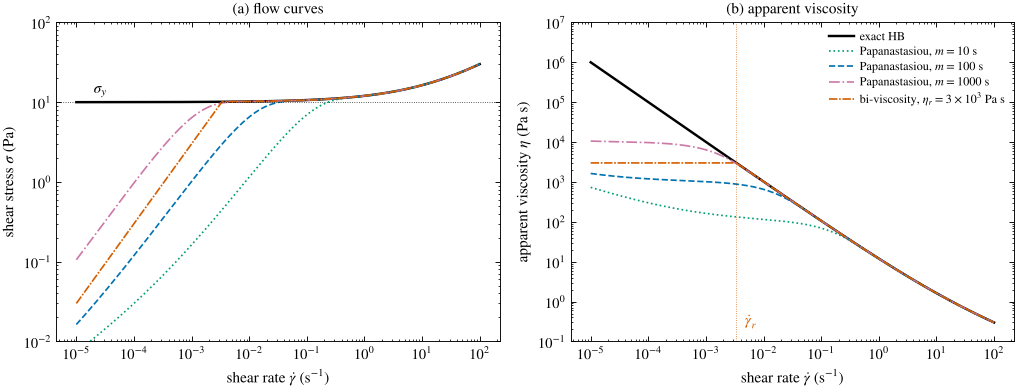

In [5]:
gd = np.logspace(-5, 2, 600)                       # same grid as scripts/fig11_regularization.py
curves = {"exact HB": eta_hb(gd)}
for mm in (10, 100, 1000):
    curves[f"Papanastasiou, $m={mm}$ s"] = eta_papanastasiou(gd, mm)
curves[r"bi-viscosity, $\eta_r=3\times10^3$ Pa s"] = eta_biviscosity(gd, eta_r)[0]

styles = [("k", "-"), (C["green"], ":"), (C["blue"], "--"), (C["purple"], "-."), (C["red"], (0, (5, 1, 1, 1)))]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.8))
for (label, eta), (col, ls) in zip(curves.items(), styles):
    lw = 1.6 if label == "exact HB" else 1.1
    ax1.loglog(gd, eta * gd, color=col, ls=ls, lw=lw, label=label)
    ax2.loglog(gd, eta, color=col, ls=ls, lw=lw, label=label)
ax1.axhline(sigma_y, color="k", lw=0.5, ls=(0, (1, 2)))
ax1.text(2e-5, sigma_y * 1.3, r"$\sigma_y$")
ax2.axvline(g_r, color=C["red"], lw=0.5, ls=(0, (1, 2)))
ax2.text(g_r * 1.4, 2.5e-1, r"$\dot\gamma_r$", color=C["red"])
ax1.set(xlabel=r"shear rate $\dot\gamma$ (s$^{-1}$)", ylabel=r"shear stress $\sigma$ (Pa)", ylim=(1e-2, 1e2), title="(a) flow curves")
ax2.set(xlabel=r"shear rate $\dot\gamma$ (s$^{-1}$)", ylabel=r"apparent viscosity $\eta$ (Pa s)", ylim=(1e-1, 1e7), title="(b) apparent viscosity")
ax2.legend(fontsize=8, loc="upper right")
fig.tight_layout()
plt.show()

In [6]:
# Compare every curve with the numbers stored with the article (data/figure_data/fig11_regularization.csv).
fd11 = pd.read_csv(FIGDATA / "fig11_regularization.csv", comment="#")
RTOL = 1e-8          # the CSV stores 10 significant digits
for label, eta in curves.items():
    xa, ya = figure_series(fd11, "(a)", label)
    xb, yb = figure_series(fd11, "(b)", label)
    assert np.allclose(xa, gd, rtol=RTOL) and np.allclose(xb, gd, rtol=RTOL)
    assert np.allclose(ya, eta * gd, rtol=RTOL), label
    assert np.allclose(yb, eta, rtol=RTOL), label
g_r_csv = fd11.loc[fd11["series"] == "bi-viscosity switching rate gamma_dot_r", "x"].item()
assert np.isclose(g_r_csv, g_r, rtol=1e-6)
sy_csv = fd11.loc[fd11["series"] == "yield stress sigma_y", "y"].item()
assert sy_csv == sigma_y
print(f"Fig. 11 check passed: all {2 * len(curves)} curves, the yield-stress line and the switch rate "
      f"gamma_dot_r = {g_r:.4e} 1/s agree with fig11_regularization.csv (relative tolerance {RTOL:g}).")

Fig. 11 check passed: all 10 curves, the yield-stress line and the switch rate gamma_dot_r = 3.3720e-03 1/s agree with fig11_regularization.csv (relative tolerance 1e-08).


**Reading the figure.** In (a) every regularized curve follows the exact flow curve at high rate, but below a rate of order $1/m$ the Papanastasiou stress falls below $\sigma_y$ and tends to zero: the material now flows at any stress. The bi-viscosity curve is a straight line of slope one (Newtonian) below $\dot\gamma_r$. In (b) the bi-viscosity viscosity saturates at $\eta_r$, whereas the Papanastasiou curves turn upward again at very low rate: this is the residual divergence of $K\dot\gamma^{\,n-1}$.

### Where does the residual divergence start?
At low rate the Papanastasiou viscosity is approximately $\sigma_y m + K\dot\gamma^{\,n-1}$. The power-law part overtakes the regularized yield part when $K\dot\gamma^{\,n-1}=\sigma_y m$, i.e. at
$$\dot\gamma_\times=\left(\frac{K}{\sigma_y m}\right)^{1/(1-n)}=\dot\gamma_y\,M^{-1/(1-n)},\qquad M=m\dot\gamma_y .$$
(The second form uses $K/\sigma_y=\dot\gamma_y^{-n}$.) This crossover is a simple estimate made for this notebook; the article states only that the term diverges. Below $\dot\gamma_\times$ a Newton solver again sees an unbounded viscosity, which is why a **viscosity cap** is needed for $n<1$, a second regularization parameter that must be reported (Sec. VII F, Table IX).

In [7]:
for mm in (10, 100, 1000):
    M = mm * gdot_y
    g_cross = (K / (sigma_y * mm)) ** (1 / (1 - n))
    assert np.isclose(g_cross, gdot_y * M ** (-1 / (1 - n)))
    # check: at g_cross the two parts of the low-rate viscosity are equal
    print(f"m = {mm:5d} s  ->  M = {M:7.0f},  crossover rate = {g_cross:.1e} 1/s,"
          f"  eta(1e-10 1/s) = {eta_papanastasiou(1e-10, mm):.2e} Pa s")

m =    10 s  ->  M =     250,  crossover rate = 4.0e-04 1/s,  eta(1e-10 1/s) = 2.00e+05 Pa s
m =   100 s  ->  M =    2500,  crossover rate = 4.0e-06 1/s,  eta(1e-10 1/s) = 2.01e+05 Pa s
m =  1000 s  ->  M =   25000,  crossover rate = 4.0e-08 1/s,  eta(1e-10 1/s) = 2.10e+05 Pa s


## 4. Why $M=m\dot\gamma_y$ matters, not $m$ alone

The parameter $m$ has units of time, so its value depends on the unit of time and, more importantly, means nothing until it is compared with a time scale of the material or the flow. Scale the rate by $\dot\gamma_y=(\sigma_y/K)^{1/n}$ and the stress by $\sigma_y$. With $x=\dot\gamma/\dot\gamma_y$ and $K\dot\gamma^n=\sigma_y x^n$, the regularized flow curve becomes
$$\frac{\sigma}{\sigma_y}=1-e^{-Mx}+x^{\,n},\qquad M=m\dot\gamma_y .$$
In scaled form the regularized law depends only on $M$ and $n$. Two materials with the same $m$ but different $\dot\gamma_y$ are regularized very differently; two materials with the same $M$ are regularized identically. (For a flow with velocity scale $U$ and length $L$ the article also uses $M=mU/L$.)

Below we compare two hypothetical materials with the same $\sigma_y$ and $n$: material A is that of Fig. 11 ($\dot\gamma_y=25$ s$^{-1}$), material B has a ten times larger consistency ($\dot\gamma_y=0.25$ s$^{-1}$). The relative stress error of the regularization is
$$\frac{\sigma_{\rm HB}-\sigma_{\rm reg}}{\sigma_{\rm HB}}=\frac{e^{-Mx}}{1+x^n}.$$

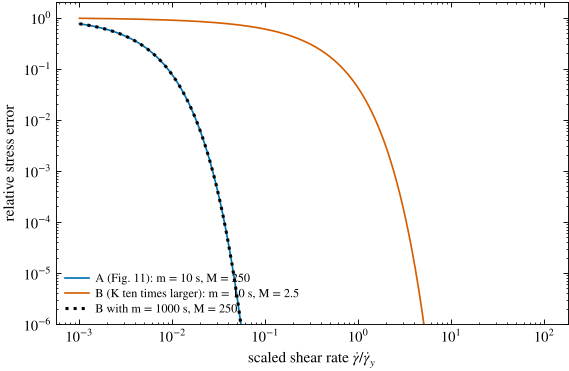

Same m, different materials: very different errors. Same M: identical curves (checked).


In [8]:
def rel_stress_error(g, sy, KK, nn, mm):
    """(sigma_HB - sigma_Papanastasiou) / sigma_HB on the yielded branch."""
    s_hb = sy + KK * g ** nn
    s_reg = sy * (-np.expm1(-mm * g)) + KK * g ** nn
    return (s_hb - s_reg) / s_hb

materials = {"A (Fig. 11)": (10.0, 2.0, 0.5), "B (K ten times larger)": (10.0, 20.0, 0.5)}
x = np.logspace(-3, 2, 300)                      # rate in units of gamma_dot_y

fig, ax = plt.subplots(figsize=(6, 3.8))
for (name, (sy, KK, nn)), col in zip(materials.items(), [C["blue"], C["red"]]):
    gy = (sy / KK) ** (1 / nn)
    ax.loglog(x, rel_stress_error(x * gy, sy, KK, nn, 10.0), color=col,
              label=f"{name}: m = 10 s, M = {10 * gy:g}")
# Material B with m chosen to give the same M as material A
sy, KK, nn = materials["B (K ten times larger)"]
gyA = (10.0 / 2.0) ** 2; gyB = (sy / KK) ** (1 / nn)
mB = 10.0 * gyA / gyB
errA = rel_stress_error(x * gyA, 10.0, 2.0, 0.5, 10.0)
errB = rel_stress_error(x * gyB, sy, KK, nn, mB)
ax.loglog(x, errB, "k:", lw=2, label=f"B with m = {mB:g} s, M = {mB * gyB:g}")
assert np.allclose(errA, errB, rtol=1e-12)        # same M -> identical scaled error
ax.set(xlabel=r"scaled shear rate $\dot\gamma/\dot\gamma_y$", ylabel="relative stress error",
       ylim=(1e-6, 2))
ax.legend(fontsize=8, loc="lower left")
plt.show()
print("Same m, different materials: very different errors. Same M: identical curves (checked).")

The same $m=10$ s that regularizes material A sharply ($M=250$) barely regularizes material B ($M=2.5$): at $\dot\gamma=\dot\gamma_y$ material B's stress is still off by about 4%. With $m$ rescaled to give the same $M$, the two curves coincide exactly. A regularization parameter should therefore always be reported in a dimensionless form, $M=m\dot\gamma_y$ or $mU/L$ (Table IX asks for "complete expression and dimensionless settings").

The three values used in Fig. 11 correspond to:

In [9]:
for mm in (10, 100, 1000):
    M = mm * gdot_y
    # the yield term reaches 95 % of sigma_y when m*gdot = ln 20 ~ 3.0
    print(f"m = {mm:5d} s  ->  M = m*gamma_dot_y = {M:8.0f};  yield term at 95 % of sigma_y "
          f"for gamma_dot = {np.log(20) / mm:.1e} 1/s = {np.log(20) / M:.1e} gamma_dot_y")

m =    10 s  ->  M = m*gamma_dot_y =      250;  yield term at 95 % of sigma_y for gamma_dot = 3.0e-01 1/s = 1.2e-02 gamma_dot_y
m =   100 s  ->  M = m*gamma_dot_y =     2500;  yield term at 95 % of sigma_y for gamma_dot = 3.0e-02 1/s = 1.2e-03 gamma_dot_y
m =  1000 s  ->  M = m*gamma_dot_y =    25000;  yield term at 95 % of sigma_y for gamma_dot = 3.0e-03 1/s = 1.2e-04 gamma_dot_y


### Observation time: creep below the yield stress
A regularized material is never rigid. Under a constant sub-yield stress $\sigma<\sigma_y$ it flows at a small rate and accumulates strain of order $\sigma t/\eta_0$, where $\eta_0$ is its low-rate viscosity (article, end of Sec. VII F). The cell below solves $\sigma_y(1-e^{-m\dot\gamma})+K\dot\gamma^n=\sigma$ for the creep rate at $\sigma=0.5\,\sigma_y$ and reports the strain accumulated in one hour and in one day. The numbers are an illustration made for this notebook with the Fig. 11 parameters.

In [10]:
sigma_applied = 0.5 * sigma_y
print(f"applied stress = {sigma_applied:g} Pa (half the yield stress)")
for mm in (10, 100, 1000, 1e4, 1e5):
    rate = brentq(lambda g: sigma_y * (-np.expm1(-mm * g)) + K * g ** n - sigma_applied, 0, 1e3, xtol=1e-18)
    print(f"  Papanastasiou m = {mm:8.0f} s (M = {mm * gdot_y:9.0f}): creep rate {rate:.2e} 1/s, "
          f"strain after 1 h {rate * 3600:9.3g}, after 1 day {rate * 86400:9.3g}")
rate_bv = sigma_applied / eta_r
print(f"  bi-viscosity eta_r = {eta_r:g} Pa s: creep rate {rate_bv:.2e} 1/s, strain after 1 day {rate_bv * 86400:.3g}")

applied stress = 5 Pa (half the yield stress)
  Papanastasiou m =       10 s (M =       250): creep rate 6.00e-02 1/s, strain after 1 h       216, after 1 day  5.18e+03
  Papanastasiou m =      100 s (M =      2500): creep rate 6.61e-03 1/s, strain after 1 h      23.8, after 1 day       571
  Papanastasiou m =     1000 s (M =     25000): creep rate 6.83e-04 1/s, strain after 1 h      2.46, after 1 day        59
  Papanastasiou m =    10000 s (M =    250000): creep rate 6.90e-05 1/s, strain after 1 h     0.248, after 1 day      5.96
  Papanastasiou m =   100000 s (M =   2500000): creep rate 6.92e-06 1/s, strain after 1 h    0.0249, after 1 day     0.598
  bi-viscosity eta_r = 3000 Pa s: creep rate 1.67e-03 1/s, strain after 1 day 144


Even with $M=2.5\times10^6$ the "solid" accumulates a strain of order one in a day. A regularization that is adequate for a pumping calculation lasting seconds can therefore be useless for shelf stability or particle suspension over days.

## 5. Pipe flow of the HB–Papanastasiou law

### The exact solution
In fully developed pipe flow, momentum balance fixes the shear stress, whatever the rheology:
$$\sigma(r)=\sigma_w\frac{r}{R},\qquad \sigma_w=\frac{GR}{2},$$
with $G$ the pressure gradient (Sec. VII A). The exact HB material is unyielded for $r<r_p=R\sigma_y/\sigma_w\equiv R\phi$, and integrating $\dot\gamma=-{\rm d}u/{\rm d}r$ with no slip at $r=R$ gives **Eq. (18)**,
$$u(r)=\frac{n}{n+1}\frac{R}{\sigma_w}\left(\frac{1}{K}\right)^{1/n}\left[(\sigma_w-\sigma_y)^{\frac{n+1}{n}}-\left(\sigma_w\frac{r}{R}-\sigma_y\right)^{\frac{n+1}{n}}\right],\qquad r\ge r_p,$$
with $u=u(r_p)$ in the plug, and the flow rate **Eq. (19)**,
$$Q=\pi R^3 n\left(\frac{\sigma_w}{K}\right)^{1/n}(1-\phi)^{\frac{n+1}{n}}\left[\frac{(1-\phi)^2}{3n+1}+\frac{2\phi(1-\phi)}{2n+1}+\frac{\phi^2}{n+1}\right].$$

### The regularized solution
Because the stress is known at every radius, the regularized problem is solved point by point: at each $r$ find the rate from $\sigma_y(1-e^{-m\dot\gamma})+K\dot\gamma^n=\sigma(r)$ (one root, because the left side increases monotonically), then integrate the rate from the wall inward. There is no plug: the rate is small but positive at every $r>0$.

Following Fig. 12 we use scaled units $\sigma_y=K=R=1$, so that $\dot\gamma_y=1$ and $M=m$ numerically, with $n=0.5$ and $\phi=0.5$ ($\sigma_w=2\sigma_y$).

In [11]:
# Scaled units of Fig. 12: sigma_y = K = R = 1, so gamma_dot_y = 1 and M = m.
sy_s, K_s, n_s, R_s, phi = 1.0, 1.0, 0.5, 1.0, 0.5
sigma_w = sy_s / phi
r = np.linspace(0.0, R_s, 2001)                  # same radial grid as the script
sigma_r = sigma_w * r / R_s                       # momentum balance: linear stress

def u_eq18(r):
    """Exact HB velocity, Eq. (18); constant inside the plug."""
    excess = np.clip(sigma_w * r / R_s - sy_s, 0.0, None)
    return n_s / (n_s + 1) * R_s / sigma_w * (1 / K_s) ** (1 / n_s) * (
        (sigma_w - sy_s) ** ((n_s + 1) / n_s) - excess ** ((n_s + 1) / n_s))

def Q_eq19(sw, sy, KK, nn, RR):
    """Exact HB flow rate, Eq. (19)."""
    ph = sy / sw
    return np.pi * RR**3 * nn * (sw / KK) ** (1 / nn) * (1 - ph) ** ((nn + 1) / nn) * (
        (1 - ph) ** 2 / (3 * nn + 1) + 2 * ph * (1 - ph) / (2 * nn + 1) + ph**2 / (nn + 1))

def velocity_from_rate(g):
    """u(r) = integral from r to R of gamma_dot (no slip at the wall), trapezoidal rule."""
    return -cumulative_trapezoid(g[::-1], r[::-1], initial=0)[::-1]

def rate_regularized(s, M):
    """Rate of the HB-Papanastasiou law at stress s (scaled units)."""
    if s <= 0:
        return 0.0
    return brentq(lambda g: sy_s * (1 - np.exp(-M * g)) + K_s * g**n_s - s, 0.0, 1e6)

g_exact = np.where(sigma_r > sy_s, (np.clip(sigma_r - sy_s, 0, None) / K_s) ** (1 / n_s), 0.0)
u_exact = velocity_from_rate(g_exact)

### Verifying the exact solution and its limits
We check the numerical integration against Eq. (18), the flow rate against Eq. (19), and Eq. (19) against its three classical limits: Hagen–Poiseuille (Newtonian, $\sigma_y=0$, $n=1$: $Q=\pi R^3\sigma_w/4K$), the power law ($\phi=0$: $Q=\pi R^3 n(\sigma_w/K)^{1/n}/(3n+1)$) and the Buckingham–Reiner equation (Bingham, $n=1$: $Q=\frac{\pi R^3\sigma_w}{4K}\left(1-\frac{4}{3}\phi+\frac{1}{3}\phi^4\right)$).

In [12]:
# Numerical profile vs Eq. (18)
err18 = np.max(np.abs(u_exact - u_eq18(r))) / u_eq18(r).max()
print(f"trapezoidal profile vs Eq. (18): max relative difference {err18:.1e}")
assert err18 < 1e-5

# Flow rate: Q = 2 pi * integral of u r dr vs Eq. (19)
Q_num = np.trapezoid(2 * np.pi * r * u_eq18(r), r)
print(f"Q from the profile {Q_num:.8f}, Eq. (19) {Q_eq19(sigma_w, sy_s, K_s, n_s, R_s):.8f}")
assert np.isclose(Q_num, Q_eq19(sigma_w, sy_s, K_s, n_s, R_s), rtol=1e-6)

# Limits of Eq. (19)
sw, KK, RR = 3.0, 1.7, 0.8
assert np.isclose(Q_eq19(sw, 0.0, KK, 1.0, RR), np.pi * RR**3 * sw / (4 * KK))                     # Newtonian
assert np.isclose(Q_eq19(sw, 0.0, KK, 0.4, RR), np.pi * RR**3 * 0.4 * (sw / KK) ** 2.5 / (3 * 0.4 + 1))  # power law
for ph in (0.1, 0.5, 0.9):                                                                           # Bingham
    assert np.isclose(Q_eq19(sw, ph * sw, KK, 1.0, RR), np.pi * RR**3 * sw / (4 * KK) * (1 - 4 * ph / 3 + ph**4 / 3))
print("Eq. (19) reproduces the Newtonian, power-law and Buckingham-Reiner limits.")

trapezoidal profile vs Eq. (18): max relative difference 5.0e-07
Q from the profile 0.40578890, Eq. (19) 0.40578905
Eq. (19) reproduces the Newtonian, power-law and Buckingham-Reiner limits.


### Regularized profiles for increasing $M$

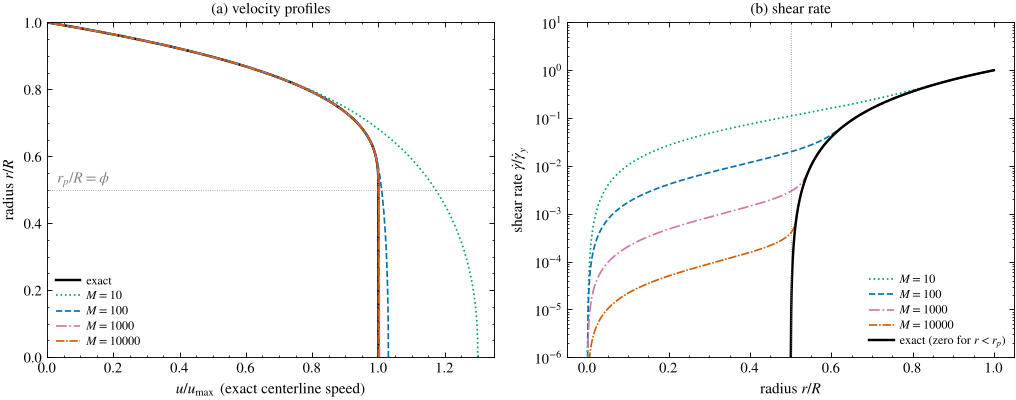

In [13]:
M_values = [10, 100, 1000, 10000]                 # as in Fig. 12(a)
g_reg = {M: np.array([rate_regularized(s, M) for s in sigma_r]) for M in M_values}
u_reg = {M: velocity_from_rate(g) for M, g in g_reg.items()}
u_max = u_exact.max()                              # centerline speed of the exact solution

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.9))
ax1.plot(u_exact / u_max, r, "k", lw=1.6, label="exact")
for M, (col, ls) in zip(M_values, [(C["green"], ":"), (C["blue"], "--"), (C["purple"], "-."), (C["red"], (0, (5, 1, 1, 1)))]):
    ax1.plot(u_reg[M] / u_max, r, color=col, ls=ls, label=f"$M={M:g}$")
    ax2.semilogy(r, np.maximum(g_reg[M], 1e-12), color=col, ls=ls, label=f"$M={M:g}$")
ax2.semilogy(r, np.where(g_exact > 0, g_exact, np.nan), "k", lw=1.6, label="exact (zero for $r<r_p$)")
for ax in (ax1,):
    ax.axhline(phi, color=C["grey"], lw=0.5, ls=(0, (1, 2)))
    ax.text(0.03, phi + 0.02, r"$r_p/R=\phi$", color=C["grey"])
ax2.axvline(phi, color=C["grey"], lw=0.5, ls=(0, (1, 2)))
ax1.set(xlabel=r"$u/u_{\max}$ (exact centerline speed)", ylabel=r"radius $r/R$", xlim=(0, 1.35), ylim=(0, 1), title="(a) velocity profiles")
ax2.set(xlabel=r"radius $r/R$", ylabel=r"shear rate $\dot\gamma/\dot\gamma_y$", ylim=(1e-6, 10), title="(b) shear rate")
ax1.legend(loc="lower left", fontsize=8); ax2.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

Panel (a) is the article's Fig. 12(a). At $M=10$ the centerline speed is 30% too high; by $M=10^4$ the profile is indistinguishable from the exact one at this scale. Panel (b) shows what the profile hides: inside $r<\phi R$, where the exact rate is zero, the regularized rate is small but never zero, and it decreases almost in proportion to $1/M$. The regularized "plug" is a slowly shearing region.

### How fast does the regularized solution converge?

        M  centerline speed error  flow-rate error  max rate in exact plug (/gamma_dot_y)
1.000e+01               3.000e-01        1.135e-01                              1.100e-01
3.000e+01               1.000e-01        2.938e-02                              4.983e-02
1.000e+02               3.000e-02        7.423e-03                              1.959e-02
3.000e+02               1.000e-02        2.254e-03                              8.008e-03
1.000e+03               3.000e-03        6.370e-04                              2.903e-03
3.000e+03               1.000e-03        2.058e-04                              1.122e-03
1.000e+04               3.000e-04        6.056e-05                              3.878e-04
1.000e+05               3.000e-05        5.959e-06                              4.834e-05

fitted log-log slopes for M >= 300: centerline speed -1.000, flow rate -1.021


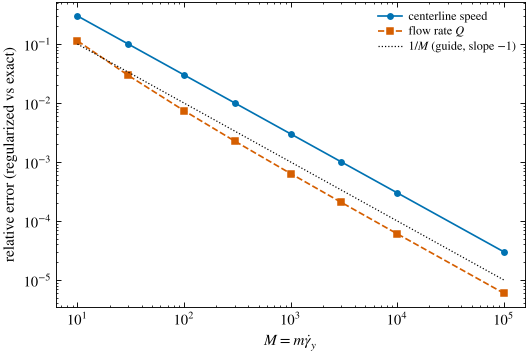

In [14]:
Q_exact = Q_eq19(sigma_w, sy_s, K_s, n_s, R_s)
M_scan = np.array([10, 30, 100, 300, 1000, 3000, 1e4, 1e5])
err_u, err_Q, max_rate_plug = [], [], []
for M in M_scan:
    g = np.array([rate_regularized(s, M) for s in sigma_r])
    u = velocity_from_rate(g)
    err_u.append(u[0] / u_exact[0] - 1)
    err_Q.append(np.trapezoid(2 * np.pi * r * u, r) / Q_exact - 1)
    max_rate_plug.append(g[sigma_r < sy_s].max())
err_u, err_Q = np.array(err_u), np.array(err_Q)
print(pd.DataFrame({"M": M_scan, "centerline speed error": err_u, "flow-rate error": err_Q,
                    "max rate in exact plug (/gamma_dot_y)": max_rate_plug}).to_string(index=False, float_format="%.3e"))

slope_u = np.polyfit(np.log(M_scan[3:]), np.log(err_u[3:]), 1)[0]
slope_Q = np.polyfit(np.log(M_scan[3:]), np.log(err_Q[3:]), 1)[0]
print(f"\nfitted log-log slopes for M >= 300: centerline speed {slope_u:.3f}, flow rate {slope_Q:.3f}")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.loglog(M_scan, err_u, "o-", color=C["blue"], label="centerline speed")
ax.loglog(M_scan, err_Q, "s--", color=C["red"], label="flow rate $Q$")
ax.loglog(M_scan, 1 / M_scan, "k:", lw=0.8, label="$1/M$ (guide, slope $-1$)")
ax.set(xlabel=r"$M=m\dot\gamma_y$", ylabel="relative error (regularized vs exact)")
ax.legend(fontsize=8)
plt.show()

For this flow both integral quantities converge like $1/M$ (slope $-1$), the flow rate with a smaller constant. This is a numerical observation for a one-dimensional problem in which the stress is known exactly; it is not a general error estimate. In two- and three-dimensional flows the stress is part of the solution, and the article notes that stresses and yield surfaces converge more weakly than velocities (Frigaard and Nouar, 2005); for the Bingham problem, Grinevich and Olshanskii (2009) bound the strain-rate error by $C\varepsilon^{1/2}$ in the energy norm, where $\varepsilon$ is their regularization parameter. Increasing $M$ also worsens the conditioning of the discrete problem, so mesh and $M$ have to be refined together.

## 6. Where is the plug? Rate-based versus stress-based criteria

A regularized computation produces no region with $\dot\gamma=0$, so a plug has to be *defined*. Two rules are common:
* **rate criterion**: call a point unyielded if $\dot\gamma<\varepsilon$ for a chosen threshold $\varepsilon$;
* **stress criterion**: call a point unyielded if $\sigma<\sigma_y$.

In the pipe the HB–Papanastasiou stress is a monotone function of the rate, $\sigma_{\rm reg}(\dot\gamma)=\sigma_y(1-e^{-m\dot\gamma})+K\dot\gamma^n$, and the stress is $\sigma_w r/R$. Hence $\dot\gamma<\varepsilon$ exactly where $\sigma_w r/R<\sigma_{\rm reg}(\varepsilon)$, which gives **Eq. (30)**:
$$\frac{r_\varepsilon}{R}=\min\left\{1,\ \frac{\sigma_y\left(1-e^{-m\varepsilon}\right)+K\varepsilon^n}{\sigma_w}\right\}.$$
First we check Eq. (30) against a direct classification of the computed rate field.

In [15]:
def r_eps_eq30(eps, M, sy=sy_s, KK=K_s, nn=n_s, sw=sigma_w):
    """Rate-based plug radius r_eps/R, Eq. (30) (scaled units: eps in units of gamma_dot_y)."""
    return np.minimum(1.0, (sy * (-np.expm1(-M * eps)) + KK * eps**nn) / sw)

for M in M_values:
    for eps in (1e-2, 1e-3):
        unyielded = r[g_reg[M] < eps]                  # classify the computed field
        r_num = unyielded.max() if unyielded.size else 0.0
        r30 = r_eps_eq30(eps, M)
        assert abs(r_num - r30) <= (r[1] - r[0]) + 1e-12  # agreement to one grid spacing
        print(f"M = {M:6g}, eps = {eps:g}:  classified field r/R = {r_num:.4f},  Eq. (30) = {r30:.4f}")
print("Eq. (30) matches the classified rate field to within one grid spacing.")

M =     10, eps = 0.01:  classified field r/R = 0.0975,  Eq. (30) = 0.0976
M =     10, eps = 0.001:  classified field r/R = 0.0205,  Eq. (30) = 0.0208
M =    100, eps = 0.01:  classified field r/R = 0.3660,  Eq. (30) = 0.3661
M =    100, eps = 0.001:  classified field r/R = 0.0630,  Eq. (30) = 0.0634
M =   1000, eps = 0.01:  classified field r/R = 0.5495,  Eq. (30) = 0.5500
M =   1000, eps = 0.001:  classified field r/R = 0.3315,  Eq. (30) = 0.3319
M =  10000, eps = 0.01:  classified field r/R = 0.5495,  Eq. (30) = 0.5500
M =  10000, eps = 0.001:  classified field r/R = 0.5155,  Eq. (30) = 0.5158
Eq. (30) matches the classified rate field to within one grid spacing.


### The two limits
Read Eq. (30) in the two possible orders:
* **fixed $m$, then $\varepsilon\to0$**: $1-e^{-m\varepsilon}\to0$ and $K\varepsilon^n\to0$, so $r_\varepsilon\to0$. With a fine enough threshold the regularized pipe has *no* plug at all, because every point creeps.
* **fixed $\varepsilon$, then $m\to\infty$**: $1-e^{-m\varepsilon}\to1$, so $r_\varepsilon/R\to\phi+K\varepsilon^n/\sigma_w$, larger than the true plug radius $\phi$.

The ideal radius $\phi$ is recovered only when $\varepsilon\to0$ **and** $m\varepsilon\to\infty$ together. The limits do not commute. The table below evaluates Eq. (30) along both orders and along two joint paths.

In [16]:
rows = []
for M in (1e1, 1e2, 1e3, 1e4, 1e5, 1e6):
    rows.append({"M": M,
                 "eps=1e-3 fixed": r_eps_eq30(1e-3, M),
                 "eps=1/M (M*eps=1)": r_eps_eq30(1 / M, M),
                 "eps=M^-1/2 (M*eps->inf)": r_eps_eq30(M**-0.5, M)})
table = pd.DataFrame(rows)
print("r_eps/R from Eq. (30); exact plug radius phi =", phi)
print(table.to_string(index=False, float_format="%.4f"))

eps_scan = np.logspace(-1, -8, 8)
print("\nfixed M = 1e3, eps = 1e-1 ... 1e-8:", np.round(r_eps_eq30(eps_scan, 1e3), 4))

# Limits stated in the article, checked numerically
assert np.isclose(r_eps_eq30(1e-3, 1e12), phi + K_s * 1e-3**n_s / sigma_w)    # m -> inf at fixed eps
assert r_eps_eq30(1e-14, 1e3) < 1e-6                                           # eps -> 0 at fixed m
assert np.isclose(r_eps_eq30(1e-12, 1e18), phi, atol=1e-6)                    # joint limit with m*eps -> inf
assert np.isclose(r_eps_eq30(1e-12, 1e12), (1 - np.exp(-1)) * phi, atol=1e-5)  # m*eps = 1: wrong limit
print("limits checked: phi + K eps^n/sigma_w, 0, phi, and (1 - 1/e) phi along M*eps = 1")

r_eps/R from Eq. (30); exact plug radius phi = 0.5
           M  eps=1e-3 fixed  eps=1/M (M*eps=1)  eps=M^-1/2 (M*eps->inf)
     10.0000          0.0208             0.4742                   0.7600
    100.0000          0.0634             0.3661                   0.6581
   1000.0000          0.3319             0.3319                   0.5889
  10000.0000          0.5158             0.3211                   0.5500
 100000.0000          0.5158             0.3176                   0.5281
1000000.0000          0.5158             0.3166                   0.5158

fixed M = 1e3, eps = 1e-1 ... 1e-8: [6.581e-01 5.500e-01 3.319e-01 5.260e-02 6.600e-03 1.000e-03 2.000e-04
 1.000e-04]
limits checked: phi + K eps^n/sigma_w, 0, phi, and (1 - 1/e) phi along M*eps = 1


Along the path $\varepsilon=1/M$ the product $m\varepsilon$ stays equal to one and the radius converges to the *wrong* value $(1-e^{-1})\phi\approx0.63\phi$; along $\varepsilon=M^{-1/2}$ it converges to $\phi$, but slowly, because the excess $K\varepsilon^n/\sigma_w=M^{-1/4}/2$ decays slowly. At fixed $M=10^3$, refining the threshold from $10^{-1}$ to $10^{-8}$ shrinks the apparent plug from larger than $\phi$ to almost nothing.

The **stress criterion** $\sigma<\sigma_y$ gives $r/R=\phi$ for every $M$. In the pipe this is not a virtue of the criterion: the pipe stress $\sigma_w r/R$ is fixed by momentum balance, independently of the rheology, so the regularized and exact stress fields coincide. In multidimensional flows the stress is computed with the regularized law and inherits its error. The practical rule of Sec. VII G is to **label every plotted plug region with the rule used to define it**.

## 7. Reproducing Fig. 12 and checking it against the figure data

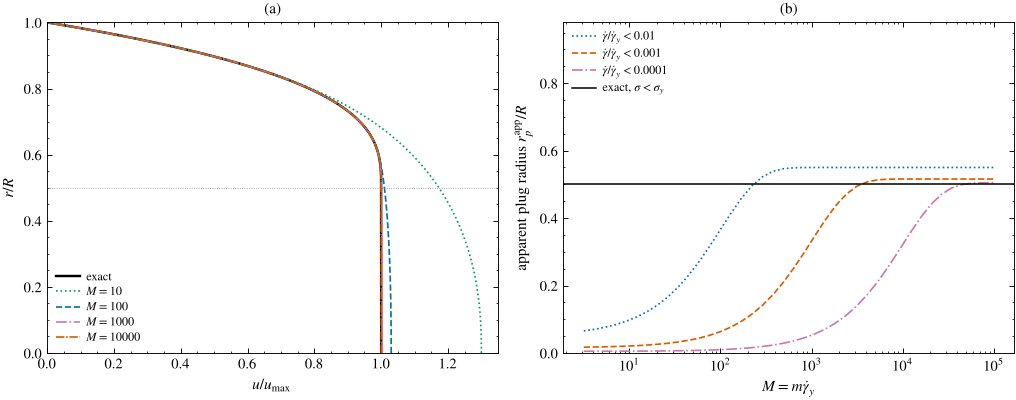

In [17]:
M_grid = np.logspace(0.5, 5, 40)                   # same grid as scripts/fig12_hbp_pipe.py
eps_list = [1e-2, 1e-3, 1e-4]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.9))
ax1.plot(u_exact / u_max, r, "k", lw=1.6, label="exact")
for M, (col, ls) in zip(M_values, [(C["green"], ":"), (C["blue"], "--"), (C["purple"], "-."), (C["red"], (0, (5, 1, 1, 1)))]):
    ax1.plot(u_reg[M] / u_max, r, color=col, ls=ls, label=f"$M={M:g}$")
ax1.axhline(phi, color=C["grey"], lw=0.5, ls=(0, (1, 2)))
ax1.set(xlabel=r"$u/u_{\max}$", ylabel=r"$r/R$", xlim=(0, 1.35), ylim=(0, 1), title="(a)")
ax1.legend(loc="lower left", fontsize=8)
for eps, (col, ls) in zip(eps_list, [(C["blue"], ":"), (C["red"], "--"), (C["purple"], "-.")]):
    ax2.semilogx(M_grid, r_eps_eq30(eps, M_grid), color=col, ls=ls, label=rf"$\dot\gamma/\dot\gamma_y<{eps:g}$")
ax2.axhline(phi, color="k", lw=1.0, label=r"exact, $\sigma<\sigma_y$")
ax2.set(xlabel=r"$M=m\dot\gamma_y$", ylabel=r"apparent plug radius $r_p^{\rm app}/R$", ylim=(0, 0.98), title="(b)")
ax2.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

In [18]:
fd12 = pd.read_csv(FIGDATA / "fig12_hbp_pipe.csv", comment="#")
TOL = 1e-8
x, y = figure_series(fd12, "(a)", "exact")
assert np.allclose(x, u_exact / u_max, atol=TOL) and np.allclose(y, r, atol=TOL)
for M in M_values:
    x, y = figure_series(fd12, "(a)", f"$M={M:g}$")
    assert np.allclose(x, u_reg[M] / u_max, atol=TOL), M
for eps in eps_list:
    x, y = figure_series(fd12, "(b)", rf"$\dot\gamma/\dot\gamma_y<{eps:g}$")
    assert np.allclose(x, M_grid, rtol=TOL) and np.allclose(y, r_eps_eq30(eps, M_grid), atol=TOL), eps
assert fd12.loc[fd12["series"] == r"exact, $\sigma<\sigma_y$", "y"].item() == phi
print(f"Fig. 12 check passed: 5 velocity profiles and 3 plug-radius curves agree with "
      f"fig12_hbp_pipe.csv to an absolute tolerance of {TOL:g}.")

Fig. 12 check passed: 5 velocity profiles and 3 plug-radius curves agree with fig12_hbp_pipe.csv to an absolute tolerance of 1e-08.


## Try it yourself

**Exercise 1 — change the unit of time.** Express the Fig. 11 material with time in minutes: $K$ becomes $K\,60^{-n}$ (Pa min$^n$) and $m$ becomes $m/60$ (min). Compute $\dot\gamma_y$ (now in min$^{-1}$) and $M$, and confirm that $M$ is unchanged and that the scaled flow curve $\sigma/\sigma_y$ versus $\dot\gamma/\dot\gamma_y$ is identical.
*Hint:* reuse `rel_stress_error` with the new $K$ and $m$, and the rate expressed in min$^{-1}$.

**Exercise 2 — a joint path that works.** Choose $\varepsilon=M^{-1/3}$ and $\varepsilon=10/M$. Use Eq. (30) to find, for each path, the limit of $r_\varepsilon/R$ as $M\to\infty$. Which converges to $\phi$, and why?
*Hint:* look at what happens to $m\varepsilon$ along each path.

**Exercise 3 — the bi-viscosity plug.** For the bi-viscosity model in the scaled pipe ($\sigma_y=K=R=1$, $n=0.5$, $\phi=0.5$), show that the rate criterion gives $r_\varepsilon/R=\min\{1,\eta_r\varepsilon/\sigma_w\}$ as long as $\varepsilon<\dot\gamma_r$. Plot $r_\varepsilon/R$ against $\eta_r$ for $\varepsilon=10^{-3}$ and find the $\eta_r$ above which this formula no longer applies.
*Hint:* below the switch rate the bi-viscosity material is Newtonian with viscosity $\eta_r$, so $\dot\gamma=\sigma/\eta_r$.

**Exercise 4 — the viscosity cap.** For the Fig. 11 material with $m=1000$ s, what viscosity cap $\eta_{\max}$ would make the capped Papanastasiou viscosity, $\min\{\eta,\eta_{\max}\}$, differ from the uncapped one only below $\dot\gamma=10^{-6}$ s$^{-1}$?

<details><summary>Solutions (click to expand)</summary>

1. $\dot\gamma_y$ becomes $25\times60=1500$ min$^{-1}$ and $m=1000/60$ min for $m=1000$ s; $M=m\dot\gamma_y$ is unchanged (25 000), and the scaled curves coincide to machine precision (see the commented cell below).
2. For $\varepsilon=M^{-1/3}$, $m\varepsilon=M^{2/3}\to\infty$ and $\varepsilon\to0$, so $r_\varepsilon\to\phi$. For $\varepsilon=10/M$, $m\varepsilon=10$ stays finite, so $r_\varepsilon/R\to(1-e^{-10})\phi$, which differs from $\phi$ by only $4.5\times10^{-5}\phi$ but is still the wrong limit in principle.
3. With $\dot\gamma=\sigma_w(r/R)/\eta_r<\varepsilon$ one gets $r/R<\eta_r\varepsilon/\sigma_w$. The formula needs $\varepsilon<\dot\gamma_r$, and $\dot\gamma_r$ decreases as $\eta_r$ grows ($\eta_r\dot\gamma_r=\sigma_y+K\dot\gamma_r^n$), so it fails once $\dot\gamma_r(\eta_r)<\varepsilon$, here above $\eta_r\approx1.03\times10^3$ in scaled units. Above that the rate criterion classifies a point as unyielded where $\sigma<\sigma_y+K\varepsilon^n$, and the radius is $\phi+K\varepsilon^n/\sigma_w\approx0.516$ for $\varepsilon=10^{-3}$.
4. The uncapped viscosity is monotone decreasing, so the cap must equal $\eta(10^{-6}\ \mathrm{s^{-1}})=\sigma_y(1-e^{-10^{-3}})/10^{-6}+K(10^{-6})^{-1/2}\approx9995+2000\approx1.20\times10^4$ Pa s.
</details>

In [19]:
# Optional solution code (uncomment to run)
# # Exercise 1
# K_min, m_min = K * 60**-n, 1000 / 60           # Pa min^n, min
# gy_min = (sigma_y / K_min) ** (1 / n)           # 1/min
# print(gy_min, m_min * gy_min, 1000 * gdot_y)    # M is the same
# xx = np.logspace(-3, 2, 50)
# print(np.allclose(rel_stress_error(xx * gy_min, sigma_y, K_min, n, m_min),
#                   rel_stress_error(xx * gdot_y, sigma_y, K, n, 1000)))
# # Exercise 2
# for M in (1e3, 1e6, 1e9, 1e12):
#     print(M, r_eps_eq30(M ** (-1 / 3), M), r_eps_eq30(10 / M, M))
# # Exercise 3
# eta_rs = np.logspace(1, 4, 200)
# g_rs = np.array([brentq(lambda g: e * g - (sy_s + K_s * g**n_s), 1e-14, 1e6) for e in eta_rs])
# r_bv = np.where(g_rs > 1e-3, np.minimum(1, eta_rs * 1e-3 / sigma_w), phi + K_s * 1e-3**n_s / sigma_w)
# plt.semilogx(eta_rs, r_bv); plt.xlabel(r"$\eta_r$ (scaled)"); plt.ylabel(r"$r_\varepsilon/R$"); plt.show()
# print("formula valid up to eta_r =", eta_rs[g_rs > 1e-3].max())
# # Exercise 4
# print("cap =", eta_papanastasiou(1e-6, 1000), "Pa s")

## Key points
* The Papanastasiou law, Eq. (29), regularizes only the yield term ($\to\sigma_y m$); for $n<1$ the term $K\dot\gamma^{\,n-1}$ still diverges, so a viscosity cap, a second parameter to report, is needed. The bi-viscosity and Souza Mendes–Dutra forms have finite low-rate viscosities. Name the formula, not just "regularized HB".
* $m$ has units of time; the meaningful parameter is $M=m\dot\gamma_y$ (or $mU/L$). The same $m$ can be excellent for one material and useless for another.
* A regularized material creeps under any stress, with strain growing like $\sigma t/\eta_0$: adequacy depends on the observation time.
* In pipe flow the HB–Papanastasiou velocity and flow rate converge to Eqs. (18)–(19) as $M$ grows (like $1/M$ in this one-dimensional example), but the exact plug is replaced by a slowly shearing core.
* A regularized plug is a classification. With the rate criterion, Eq. (30), $r_\varepsilon\to0$ as $\varepsilon\to0$ at fixed $m$, and $r_\varepsilon/R\to\phi+K\varepsilon^n/\sigma_w$ as $m\to\infty$ at fixed $\varepsilon$; $\phi$ is recovered only if $\varepsilon\to0$ and $m\varepsilon\to\infty$ together. The stress criterion is exact in the pipe only because momentum balance fixes the stress. Label plotted plugs with the rule used.

## References

The review and its repository:
* Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

* Bercovier, M., and Engelman, M. (1980). A finite-element method for incompressible non-Newtonian flows. *Journal of Computational Physics* **36**(3), 313–326. https://doi.org/10.1016/0021-9991(80)90163-1
* Buckingham, E. (1921). On plastic flow through capillary tubes. *Proceedings of the American Society for Testing Materials* **21**, 1154–1156.
* Frigaard, I. A., and Nouar, C. (2005). On the usage of viscosity regularisation methods for visco-plastic fluid flow computation. *Journal of Non-Newtonian Fluid Mechanics* **127**(1), 1–26. https://doi.org/10.1016/j.jnnfm.2005.01.003
* Grinevich, P. P., and Olshanskii, M. A. (2009). An iterative method for the Stokes-type problem with variable viscosity. *SIAM Journal on Scientific Computing* **31**(5), 3959–3978. https://doi.org/10.1137/08744803
* Herschel, W. H., and Bulkley, R. (1926). Konsistenzmessungen von Gummi-Benzollösungen. *Kolloid-Zeitschrift* **39**(4), 291–300. https://doi.org/10.1007/bf01432034
* O'Donovan, E. J., and Tanner, R. I. (1984). Numerical study of the Bingham squeeze film problem. *Journal of Non-Newtonian Fluid Mechanics* **15**(1), 75–83. https://doi.org/10.1016/0377-0257(84)80029-4
* Papanastasiou, T. C. (1987). Flows of materials with yield. *Journal of Rheology* **31**(5), 385–404. https://doi.org/10.1122/1.549926
* Souza Mendes, P. R., and Dutra, E. S. S. (2004). Viscosity function for yield-stress liquids. *Applied Rheology* **14**(6), 296–302. https://doi.org/10.1515/arh-2004-0016
* Tanner, R. I., and Milthorpe, J. F. (1983). Numerical analysis of three-dimensional viscoplastic flows. In C. Taylor, J. A. Johnson and W. R. Smith (eds.), *Numerical Methods in Laminar and Turbulent Flow*, pp. 680–690. Pineridge Press, Swansea.

### Further reading

* Burgos, G. R., Alexandrou, A. N., and Entov, V. (1999). On the determination of yield surfaces in Herschel–Bulkley fluids. *Journal of Rheology* **43**(3), 463–483. https://doi.org/10.1122/1.550992
* Chhabra, R. P., and Richardson, J. F. (2008). *Non-Newtonian Flow and Applied Rheology: Engineering Applications*, 2nd ed. Butterworth-Heinemann, Oxford.
* Liu, B. T., Muller, S. J., and Denn, M. M. (2002). Convergence of a regularization method for creeping flow of a Bingham material about a rigid sphere. *Journal of Non-Newtonian Fluid Mechanics* **102**(2), 179–191. https://doi.org/10.1016/s0377-0257(01)00177-x
* Mitsoulis, E., Abdali, S. S., and Markatos, N. C. (1993). Flow simulation of Herschel–Bulkley fluids through extrusion dies. *The Canadian Journal of Chemical Engineering* **71**(1), 147–160. https://doi.org/10.1002/cjce.5450710120